# Lorenz-63 pipeline: as-is reproduction from GitHub

**Purpose:** check whether the published code reproduces the published numbers, **with no fixes of any kind.**

- **Source:** [Mesbin/Confidence-estimation-in-NGRC](https://github.com/Mesbin/Confidence-estimation-in-NGRC), commit `a656b67` (11 Sep 2026), top-level Lorenz files.
- **Method:** each module below is the GitHub file **copied unchanged** (each cell writes the file to disk), then run in order with `%run`, exactly as `run_pipeline.py` does. Each module reads and writes its own files in `Data/` and `Results/`.
- **Proof the code is unchanged:** after the files are written, a check compares their SHA-256 fingerprints with the GitHub copies.
- **Nothing is altered:** the solver, the data split, the feature selection and the statistics are all as in the repo. If a module crashes in the repo, it crashes here too.
- **At the end:** the outputs are compared with the numbers in the paper and in the repo's README.

In [1]:
import os, sys, platform, hashlib
import numpy, scipy, sklearn, pandas, matplotlib
os.makedirs("Data", exist_ok=True); os.makedirs("Results", exist_ok=True)
print("Python", platform.python_version(), "| numpy", numpy.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)
print("Working folder:", os.getcwd())

Python 3.9.13 | numpy 1.26.4 | scipy 1.13.1 | scikit-learn 1.3.0 | pandas 2.0.3 | matplotlib 3.7.2
Working folder: C:\Users\B00732999\PycharmProjects\pythonProject\ RA_work\Mesbin


## 1. Write the GitHub files unchanged

**`Module_1_lorenz63.py`**: Simulates Lorenz-63 (RK45, 100 time units, Δt = 0.01) and saves the trajectory.

In [2]:
%%writefile Module_1_lorenz63.py
"""

Module 1 : Module_1_lorenz63.py

"""

import numpy as np
import matplotlib

import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# --------------------------------------------------------------------------
# Publication figure style, imported by every module.
# 400 dpi, base font 15 pt, line width 2.8, no grid lines, no box.
# --------------------------------------------------------------------------
def apply_style():
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 400,
        "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
        "font.family": "DejaVu Sans", "font.size": 15,
        "axes.titlesize": 16, "axes.labelsize": 15,
        "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13,
        "axes.grid": False,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.linewidth": 1.6, "axes.labelpad": 8, "axes.titlepad": 12,
        "lines.linewidth": 2.8, "lines.markersize": 8, "lines.markeredgewidth": 0,
        "patch.linewidth": 0,
        "xtick.major.width": 1.6, "ytick.major.width": 1.6,
        "xtick.major.size": 6, "ytick.major.size": 6,
        "xtick.direction": "out", "ytick.direction": "out",
        "legend.frameon": False, "errorbar.capsize": 4,
    })


def save_figure(filename):
    """Save at 400 dpi, display, report."""
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()
    plt.close()
    print(f"Saved {filename}")



class Lorenz63:

    def __init__(self, sigma=10.0, rho=28.0, beta=8/3, dt=0.01, total_time=100):
        self.sigma = sigma
        self.rho = rho
        self.beta = beta
        self.dt = dt
        self.total_time = total_time

    def equations(self, t, state):
        x, y, z = state
        dx = self.sigma * (y - x)
        dy = x * (self.rho - z) - y
        dz = x * y - self.beta * z
        return [dx, dy, dz]

    def generate(self, initial_state=[1.0, 1.0, 1.0]):
        t_eval = np.arange(0, self.total_time, self.dt)
        solution = solve_ivp(
            self.equations, (0, self.total_time), initial_state,
            t_eval=t_eval, method="RK45", rtol=1e-9, atol=1e-9
        )
        self.time, self.x, self.y, self.z = solution.t, *solution.y
        return self.time, self.x, self.y, self.z

    def dataset(self):
        return np.column_stack((self.time, self.x, self.y, self.z))

    def plot_attractor(self, filename="Results/lorenz_attractor.png"):
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(projection='3d')
        ax.plot(self.x, self.y, self.z, linewidth=0.4, color="teal")
        ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
        ax.set_title("Lorenz-63 Attractor")
        plt.savefig(filename)
        plt.show()
        plt.close()
        print(f"Saved {filename}")

    def save(self, filename="Data/lorenz63_dataset.npy"):
        np.save(filename, self.dataset())
        print(f"Dataset saved as {filename}")


if __name__ == "__main__":
    apply_style()
    lorenz = Lorenz63()
    lorenz.generate()
    print("Dataset Shape:", lorenz.dataset().shape)
    lorenz.plot_attractor()
    lorenz.save()
    print("\nModule 1 Completed Successfully.")


Overwriting Module_1_lorenz63.py


**`Module_2_feature_construction.py`**: Builds the 28-feature NGRC reservoir (k = 2, s = 1, quadratic terms).

In [3]:
%%writefile Module_2_feature_construction.py
"""
Module 2 : Module_2_feature_construction.py
"""

import numpy as np
from itertools import combinations_with_replacement
from Module_1_lorenz63 import apply_style


class NGRCFeatureConstructor:

    def __init__(self, delay=2, skip=1):
        self.k = delay
        self.s = skip

    def load_dataset(self, filename="Data/lorenz63_dataset.npy"):
        data = np.load(filename)
        print("Dataset Loaded. Shape :", data.shape)
        return data

    def delay_embedding(self, data):
        X = data[:, 1:]  # drop time column
        start = self.k * self.s

        linear = np.array([
            np.concatenate([X[i - j * self.s] for j in range(self.k)])
            for i in range(start, len(X))
        ])

        print("Linear Feature Shape :", linear.shape)
        return linear

    def quadratic_features(self, linear):
        n = linear.shape[1]
        indices = list(combinations_with_replacement(range(n), 2))

        quadratic = np.stack(
            [linear[:, i] * linear[:, j] for i, j in indices],
            axis=1
        )

        print("Quadratic Feature Shape :", quadratic.shape)
        return quadratic, indices

    def total_features(self, linear, quadratic):
        reservoir = np.hstack((
            np.ones((linear.shape[0], 1)),
            linear,
            quadratic
        ))

        print("Total Reservoir Shape :", reservoir.shape)
        return reservoir

    def feature_names(self, quad_indices):
        variables = [
            "x(t)", "y(t)", "z(t)",
            "x(t-1)", "y(t-1)", "z(t-1)"
        ]

        names = ["const"] + variables

        names += [
            f"{variables[i]}²" if i == j
            else f"{variables[i]}·{variables[j]}"
            for i, j in quad_indices
        ]

        return names

    def save(self, reservoir, names):
        np.save("Data/ngrc_reservoir.npy", reservoir)
        np.save("Data/feature_names.npy", np.array(names))

        print("Reservoir Saved: Data/ngrc_reservoir.npy")
        print("Feature Names Saved: Data/feature_names.npy")


if __name__ == "__main__":

    apply_style()

    fc = NGRCFeatureConstructor(delay=2, skip=1)

    dataset = fc.load_dataset()
    linear = fc.delay_embedding(dataset)
    quadratic, quad_idx = fc.quadratic_features(linear)

    reservoir = fc.total_features(linear, quadratic)
    names = fc.feature_names(quad_idx)

    fc.save(reservoir, names)

    print("\nModule 2 Completed Successfully.")

Overwriting Module_2_feature_construction.py


**`Module_3_ridge_readout.py`**: Trains the ridge readout with `np.linalg.inv` on all samples.

In [4]:
%%writefile Module_3_ridge_readout.py
"""
Module 3 : Module_3_ridge_readout.py

"""

import numpy as np
import matplotlib.pyplot as plt
from Module_1_lorenz63 import apply_style, save_figure


class RidgeReadout:

    def __init__(self, alpha=2.5e-6):
        self.alpha = alpha
        self.Wout = None

    def load_reservoir(self, filename="Data/ngrc_reservoir.npy"):
        reservoir = np.load(filename)
        print("Reservoir Loaded. Shape :", reservoir.shape)
        return reservoir

    def load_dataset(self, filename="Data/lorenz63_dataset.npy"):
        data = np.load(filename)
        print("Dataset Loaded. Shape :", data.shape)
        return data

    def create_target(self, data, k=2, s=1):
        start = k * s
        target = data[start + 1:, 1:]  # remove time column
        print("Target Shape :", target.shape)
        return target

    def align_reservoir(self, reservoir, target):
        reservoir = reservoir[:len(target)]
        print("Aligned Reservoir Shape :", reservoir.shape)
        return reservoir

    def train(self, reservoir, target):
        
        O = reservoir.T
        Y = target.T
        identity = np.identity(O.shape[0])
        self.Wout = (Y @ O.T) @ np.linalg.inv(O @ O.T + self.alpha * identity)
        print("Training Complete. Wout Shape :", self.Wout.shape)
        return self.Wout

    def save_weights(self, filename="Data/Wout.npy"):
        np.save(filename, self.Wout)
        print(f"Weights Saved to {filename}")

    # ==========================================================
if __name__ == "__main__":
    apply_style()
    model = RidgeReadout(alpha=2.5e-6)
    reservoir = model.load_reservoir()
    dataset = model.load_dataset()
    target = model.create_target(dataset)
    reservoir = model.align_reservoir(reservoir, target)
    model.train(reservoir, target)
    model.save_weights()
    print("\nModule 3 Completed Successfully.")

Overwriting Module_3_ridge_readout.py


**`Module_4_baseline_experiment.py`**: One-step predictions and prediction error.

In [5]:
%%writefile Module_4_baseline_experiment.py
"""

Module 4 : Module_4_baseline_experiment.py

"""

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
from Module_1_lorenz63 import apply_style, save_figure


def create_target(data, k=2, s=1):
    start = k * s
    return data[start + 1:, 1:]


def align_reservoir(reservoir, target):
    return reservoir[:len(target)]


def plot_prediction_vs_true(target, prediction, n=1000):
    """One separate figure per state variable."""
    for i, lab in enumerate(["x", "y", "z"]):
        plt.figure(figsize=(11, 4.6))
        plt.plot(target[:n, i], label="True", linewidth=2.2)
        plt.plot(prediction[:n, i], "--", label="Predicted", linewidth=2.2)
        plt.xlabel("Time step"); plt.ylabel(lab)
        plt.title(f"NGRC Baseline: Prediction vs True Trajectory  ({lab})")
        plt.legend()
        save_figure(f"Results/prediction_vs_true_{lab}.png")


if __name__ == "__main__":
    apply_style()
    reservoir = np.load("Data/ngrc_reservoir.npy")
    dataset = np.load("Data/lorenz63_dataset.npy")
    Wout = np.load("Data/Wout.npy")

    target = create_target(dataset, k=2, s=1)
    reservoir = align_reservoir(reservoir, target)

    prediction = (Wout @ reservoir.T).T
    error = np.abs(target - prediction)

    mse = np.mean((prediction - target) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(prediction - target))

    print("Baseline NGRC Performance")
    print("MSE  :", mse)
    print("RMSE :", rmse)
    print("MAE  :", mae)

    np.save("Data/prediction.npy", prediction)
    np.save("Data/prediction_error.npy", error)

    pd.DataFrame([{"MSE": mse, "RMSE": rmse, "MAE": mae}]).to_csv(
        "Results/baseline_metrics.csv", index=False
    )
    print("Saved Results/baseline_metrics.csv")

    plot_prediction_vs_true(target, prediction)

    print("\nModule 4 Completed Successfully.")


Overwriting Module_4_baseline_experiment.py


**`Module_5_confidence_analysis.py`**: Confidence C = 1/(1+e), correlations on all data, heatmap and histogram.

In [6]:
%%writefile Module_5_confidence_analysis.py
"""

Module 5 : Module_5_confidence_analysis.py

"""

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_selection import mutual_info_regression
import matplotlib

import matplotlib.pyplot as plt
from Module_1_lorenz63 import apply_style, save_figure


class ConfidenceAnalysis:

    def __init__(self):
        self.reservoir = None
        self.target = None
        self.prediction = None
        self.error = None
        self.confidence = None
        self.feature_names = None

    # ==========================================================
    def load_data(self, k=2, s=1):
        self.reservoir = np.load("Data/ngrc_reservoir.npy")
        dataset = np.load("Data/lorenz63_dataset.npy")
        self.prediction = np.load("Data/prediction.npy")

        start = k * s
        self.target = dataset[start + 1:, 1:]
        self.reservoir = self.reservoir[:len(self.target)]

        print("Reservoir Shape  :", self.reservoir.shape)
        print("Prediction Shape :", self.prediction.shape)
        print("Target Shape     :", self.target.shape)

    # ==========================================================
    def compute_error_and_confidence(self):
        """ E(t) = mean_dim |y - y_hat| ; C(t) = 1 / (1 + E(t)) """
        self.error = np.mean(np.abs(self.target - self.prediction), axis=1)
        self.confidence = 1.0 / (1.0 + self.error)

        print("\nReference Confidence computed")
        print("Mean :", np.mean(self.confidence))
        print("Min  :", np.min(self.confidence))
        print("Max  :", np.max(self.confidence))

        np.save("Data/reference_confidence.npy", self.confidence)
        print("Saved Data/reference_confidence.npy")

    # ==========================================================
    def set_feature_names(self):
        self.feature_names = [f"x{i}" for i in range(self.reservoir.shape[1])]

    # ==========================================================
    def compute_correlations(self):
        if self.feature_names is None:
            self.set_feature_names()

        n_features = self.reservoir.shape[1]
        pearson_r = np.zeros(n_features)
        pearson_p = np.zeros(n_features)
        spearman_r = np.zeros(n_features)
        spearman_p = np.zeros(n_features)

        for i in range(n_features):
            col = self.reservoir[:, i]
            if np.std(col) == 0:
                pearson_r[i], pearson_p[i] = 0.0, 1.0
                spearman_r[i], spearman_p[i] = 0.0, 1.0
                continue
            pr, pp = pearsonr(col, self.confidence)
            sr, sp = spearmanr(col, self.confidence)
            pearson_r[i], pearson_p[i] = pr, pp
            spearman_r[i], spearman_p[i] = sr, sp

        print("\nComputing Mutual Information...")
        mi = mutual_info_regression(self.reservoir, self.confidence, random_state=0)

        np.save("Results/pearson_results.npy", pearson_r)
        np.save("Results/spearman_results.npy", spearman_r)
        np.save("Results/mutual_information.npy", mi)

        self.ranking = pd.DataFrame({
            "Feature": self.feature_names,
            "Pearson": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman": spearman_r,
            "Spearman_p": spearman_p,
            "Mutual_Information": mi,
        })
        self.ranking = self.ranking.reindex(
            self.ranking["Pearson"].abs().sort_values(ascending=False).index
        ).reset_index(drop=True)

        print("\nTop 10 features by |Pearson|:")
        print(self.ranking.head(10).to_string(index=False))

        self.ranking.to_csv("Results/feature_ranking.csv", index=False)
        print("Saved Results/feature_ranking.csv")

        return self.ranking

    # ==========================================================
    def compute_correlation_matrix(self):
        """ Pairwise correlation matrix among reservoir features themselves. """
        corr_matrix = np.corrcoef(self.reservoir.T)
        corr_matrix = np.nan_to_num(corr_matrix, nan=0.0)  # bias column has zero variance
        np.save("Results/correlation_matrix.npy", corr_matrix)
        print("Saved Results/correlation_matrix.npy")
        return corr_matrix

    # ==========================================================
    def plot_correlation_heatmap(self, corr_matrix, filename="Results/correlation_heatmap.png"):
        plt.figure(figsize=(10, 8))
        im = plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
        plt.colorbar(im, label="Pearson correlation")
        plt.title("Reservoir Feature Correlation Matrix")
        plt.xlabel("Feature index"); plt.ylabel("Feature index")
        plt.tight_layout()
        plt.savefig(filename)
        plt.show()
        print(f"Saved {filename}")

    # ==========================================================
    def plot_feature_ranking(self, filename="Results/feature_ranking_barplot.png", top_n=15):
        top = self.ranking.head(top_n)
        plt.figure(figsize=(10, 6))
        plt.bar(top["Feature"], top["Pearson"].abs())
        plt.xlabel("Reservoir Feature")
        plt.ylabel("|Pearson correlation| with Confidence")
        plt.title(f"Top {top_n} Reservoir Features by Confidence Correlation")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(filename)
        plt.show()
        print(f"Saved {filename}")

    # ==========================================================
    def plot_confidence_distribution(self, filename="Results/confidence_distribution.png"):
        plt.figure(figsize=(7, 5))
        plt.hist(self.confidence, bins=50, color="steelblue", edgecolor="black")
        plt.xlabel("Reference Confidence C(t)")
        plt.ylabel("Frequency")
        plt.title("Distribution of Reference Confidence")
        plt.tight_layout()
        plt.savefig(filename)
        plt.show()
        print(f"Saved {filename}")


if __name__ == "__main__":
    apply_style()
    ca = ConfidenceAnalysis()
    ca.load_data()
    ca.compute_error_and_confidence()
    ca.set_feature_names()
    ranking = ca.compute_correlations()
    corr_matrix = ca.compute_correlation_matrix()
    ca.plot_correlation_heatmap(corr_matrix)
    ca.plot_feature_ranking()
    ca.plot_confidence_distribution()

    print("\nModule 5 Completed Successfully.")


Overwriting Module_5_confidence_analysis.py


**`Module_6_feature_selection.py`**: Feature selection on the training 80% (Pearson, p-value, mutual information). Overwrites Module 5's ranking file.

In [7]:
%%writefile Module_6_feature_selection.py
"""
Module 6 : Module_6_feature_selection.py

Objective:
    Perform leakage-free confidence-related feature selection.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr
from sklearn.feature_selection import mutual_info_regression

from Module_1_lorenz63 import apply_style, save_figure


class FeatureSelector:

    def __init__(self, pearson_threshold=0.30, pvalue_threshold=0.05,
                 mi_method="median", train_fraction=0.80):

        self.pearson_threshold = pearson_threshold
        self.pvalue_threshold = pvalue_threshold
        self.mi_method = mi_method
        self.train_fraction = train_fraction

        self.reservoir = None
        self.feature_names = None
        self.confidence = None

        self.train_reservoir = None
        self.test_reservoir = None
        self.train_confidence = None
        self.test_confidence = None

        self.ranking = None
        self.selected = None
        self.selected_indices = None
        self.selected_reservoir = None

    # ---------------------------------------------------------
    # Load data
    # ---------------------------------------------------------

    def load_reservoir(self, filename="Data/ngrc_reservoir.npy"):

        self.reservoir = np.load(filename)

        self.feature_names = np.load(
            "Data/feature_names.npy",
            allow_pickle=True
        )

        print("\nReservoir Loaded. Shape:", self.reservoir.shape)
        print("Feature Names Loaded:", len(self.feature_names))

    def load_confidence(
            self,
            filename="Data/reference_confidence.npy"):

        self.confidence = np.load(filename)

        print(
            "Reference Confidence Loaded. Shape:",
            self.confidence.shape
        )

    # ---------------------------------------------------------
    # Train / test split
    # ---------------------------------------------------------

    def split_data(self):

        n = min(
            len(self.reservoir),
            len(self.confidence)
        )

        self.reservoir = self.reservoir[:n]
        self.confidence = self.confidence[:n]

        n_train = int(
            n * self.train_fraction
        )

        self.train_reservoir = self.reservoir[:n_train]
        self.test_reservoir = self.reservoir[n_train:]

        self.train_confidence = self.confidence[:n_train]
        self.test_confidence = self.confidence[n_train:]

        print("\nLeakage-Free Feature Selection Split")
        print("------------------------------------")
        print("Total samples    :", n)
        print(
            "Training samples :",
            len(self.train_reservoir)
        )
        print(
            "Test samples     :",
            len(self.test_reservoir)
        )

    # ---------------------------------------------------------
    # Feature ranking
    # ---------------------------------------------------------

    def compute_feature_ranking(self):

        X = self.train_reservoir
        C = self.train_confidence

        n_features = X.shape[1]

        pearson_values = []
        pearson_pvalues = []

        print(
            "\nCalculating Pearson correlations "
            "using TRAINING DATA ONLY..."
        )

        for i in range(n_features):

            r, p = pearsonr(
                X[:, i],
                C
            )

            pearson_values.append(r)
            pearson_pvalues.append(p)

        print(
            "Calculating Mutual Information "
            "using TRAINING DATA ONLY..."
        )

        mi_values = mutual_info_regression(
            X,
            C,
            random_state=0
        )

        self.ranking = pd.DataFrame({
            "Index": np.arange(n_features),
            "Feature": self.feature_names,
            "Pearson": pearson_values,
            "Pearson_p": pearson_pvalues,
            "Mutual_Information": mi_values
        })

        self.ranking = self.ranking.reindex(
            self.ranking["Pearson"]
            .abs()
            .sort_values(ascending=False)
            .index
        ).reset_index(drop=True)

        print("\nFeature Ranking Created")
        print("------------------------------------")
        print(self.ranking.head(10))

        self.ranking.to_csv(
            "Results/feature_ranking.csv",
            index=False
        )

    # ---------------------------------------------------------
    # Mutual information threshold
    # ---------------------------------------------------------

    def mi_threshold(self):

        if self.mi_method == "median":

            threshold = np.median(
                self.ranking["Mutual_Information"]
            )

        elif self.mi_method == "mean":

            threshold = np.mean(
                self.ranking["Mutual_Information"]
            )

        else:

            threshold = float(
                self.mi_method
            )

        print(
            "\nMutual Information Threshold:",
            threshold
        )

        return threshold

    # ---------------------------------------------------------
    # Feature selection
    # ---------------------------------------------------------

    def select(self):

        mi_threshold = self.mi_threshold()

        selected = self.ranking[
            (self.ranking["Pearson"].abs()
             >= self.pearson_threshold)
            &
            (self.ranking["Pearson_p"]
             < self.pvalue_threshold)
            &
            (self.ranking["Mutual_Information"]
             >= mi_threshold)
        ]

        if len(selected) == 0:

            print(
                "\nWarning: nothing passed thresholds."
            )

            print(
                "Falling back to top 10 "
                "features by |Pearson|."
            )

            selected = self.ranking.head(10)

        self.selected = selected.copy()

        self.selected_indices = (
            self.selected["Index"]
            .astype(int)
            .tolist()
        )

        print("\nSelected Features")
        print("------------------------------------")

        print(
            self.selected[
                [
                    "Index",
                    "Feature",
                    "Pearson",
                    "Pearson_p",
                    "Mutual_Information"
                ]
            ]
        )

        print(
            "\nNumber Selected:",
            len(self.selected_indices)
        )

    # ---------------------------------------------------------
    # Extract selected reservoir features
    # ---------------------------------------------------------

    def extract(self):

        self.selected_reservoir = (
            self.reservoir[
                :,
                self.selected_indices
            ]
        )

        print(
            "\nSelected Reservoir Shape:",
            self.selected_reservoir.shape
        )

        print(
            "Selected features determined "
            "using training data only."
        )

    # ---------------------------------------------------------
    # Save results
    # ---------------------------------------------------------

    def save(self):

        np.save(
            "Results/selected_reservoir.npy",
            self.selected_reservoir
        )

        np.save(
            "Results/selected_indices.npy",
            np.array(self.selected_indices)
        )

        self.selected.to_csv(
            "Results/selected_features.csv",
            index=False
        )

        print("\nSaved:")
        print(
            "  Results/selected_reservoir.npy"
        )
        print(
            "  Results/selected_indices.npy"
        )
        print(
            "  Results/selected_features.csv"
        )

    # ---------------------------------------------------------
    # Plot selected features
    # ---------------------------------------------------------

    def plot_selected_features(
            self,
            filename="Results/selected_features_plot.png"):

        # Keep the same selected-feature ordering
        features = self.selected.copy()

        x = np.arange(
            len(features)
        )

        # Positive = confidence
        # Negative = uncertainty
        colors = np.where(
            features["Pearson"] >= 0,
            "green",
            "red"
        )

        plt.figure(
            figsize=(12, 7)
        )

        plt.bar(
            x,
            features["Pearson"],
            color=colors
        )

        plt.axhline(
            0,
            color="black",
            linewidth=1
        )

        plt.axhline(
            self.pearson_threshold,
            color="gray",
            linestyle=":",
            linewidth=1.5
        )

        plt.axhline(
            -self.pearson_threshold,
            color="gray",
            linestyle=":",
            linewidth=1.5
        )

        plt.xticks(
            x,
            features["Feature"],
            rotation=45,
            ha="right"
        )

        plt.xlabel(
            "Selected Reservoir Feature"
        )

        plt.ylabel(
            "Pearson Correlation with Confidence"
        )

        plt.title(
            f"Selected Reservoir Features "
            f"(n={len(self.selected_indices)})\n"
            "green = confidence-encoding, "
            "red = uncertainty-encoding"
        )

        from matplotlib.patches import Patch

        legend = [
            Patch(
                facecolor="green",
                label="Confidence-encoding"
            ),
            Patch(
                facecolor="red",
                label="Uncertainty-encoding"
            )
        ]

        plt.legend(
            handles=legend
        )

        plt.tight_layout()

        save_figure(
            filename
        )

        print(
            f"Saved {filename}"
        )


# =============================================================
# Main
# =============================================================

if __name__ == "__main__":

    apply_style()

    fs = FeatureSelector(
        pearson_threshold=0.30,
        pvalue_threshold=0.05,
        mi_method="median",
        train_fraction=0.80
    )

    fs.load_reservoir()
    fs.load_confidence()
    fs.split_data()
    fs.compute_feature_ranking()
    fs.select()
    fs.extract()
    fs.save()
    fs.plot_selected_features()

    print(
        "\nModule 6 Completed Successfully."
    )

Overwriting Module_6_feature_selection.py


**`Module_7_confidence_estimator.py`**: Ridge confidence estimator, 80/20 split, metrics and figures.

In [8]:
%%writefile Module_7_confidence_estimator.py
"""
Module 7 : Module_7_confidence_estimator.py

Objective:
    Estimate confidence directly from the selected reservoir features.

Leakage-free workflow:
    - Load selected reservoir
    - Load reference confidence
    - Split into training and test sets
    - Train confidence estimator using training data only
    - Predict confidence on unseen test data
    - Evaluate: RMSE, MAE, R2, Pearson correlation
    - Generate plots
"""

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

from scipy.stats import pearsonr
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from Module_1_lorenz63 import apply_style, save_figure


class ConfidenceEstimator:

    def __init__(self, alpha=1e-3):
        self.alpha = alpha
        self.model = Ridge(alpha=alpha)

    def load_data(self):

        S = np.load("Results/selected_reservoir.npy")
        C = np.load("Data/reference_confidence.npy")

        n = min(len(S), len(C))

        S = S[:n]
        C = C[:n]

        print("\nConfidence Estimator Data")
        print("------------------------------------")
        print("Selected reservoir shape :", S.shape)
        print("Reference confidence shape:", C.shape)
        print("Total samples            :", n)

        return S, C

    def split(self, S, C, train_fraction=0.80):

        n_train = int(len(S) * train_fraction)

        S_train = S[:n_train]
        S_test = S[n_train:]

        C_train = C[:n_train]
        C_test = C[n_train:]

        print("\nTrain / Test Split")
        print("------------------------------------")
        print("Training samples :", len(S_train))
        print("Test samples     :", len(S_test))

        return S_train, S_test, C_train, C_test

    def train(self, S_train, C_train):

        # Selected reservoir features → reference confidence
        self.model.fit(S_train, C_train)

        print("\nConfidence Estimator Trained")
        print("Model: Ridge")
        print("Alpha:", self.alpha)

    def predict(self, S):

        return self.model.predict(S)

    def evaluate(self, C_true, C_hat):

        rmse = np.sqrt(mean_squared_error(C_true, C_hat))
        mae = mean_absolute_error(C_true, C_hat)
        r2 = r2_score(C_true, C_hat)
        r, p = pearsonr(C_true, C_hat)

        metrics = {
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2,
            "Pearson_r": r,
            "Pearson_p": p
        }

        print("\nConfidence Estimator Evaluation")
        print("------------------------------------")

        for key, value in metrics.items():
            print(f"{key:12s}: {value:.6f}")

        return metrics

    def save_model(self, filename="Results/confidence_model.pkl"):

        with open(filename, "wb") as f:
            pickle.dump(self.model, f)

        print("\nModel saved to:", filename)

    def save_metrics(self, metrics,
                     filename="Results/confidence_metrics.csv"):

        pd.DataFrame([metrics]).to_csv(filename, index=False)

        print("Metrics saved to:", filename)

    def save_predictions(self, C_true, C_hat,
                         filename="Results/confidence_prediction.csv"):

        prediction_table = pd.DataFrame({
            "test_time_index": np.arange(len(C_true)),
            "reference_confidence": C_true,
            "estimated_confidence": C_hat
        })

        prediction_table.to_csv(filename, index=False)

        print("Predictions saved to:", filename)

    def plot_comparison(self, C_true, C_hat, n=1000):

        n_plot = min(n, len(C_true))

        # Reference vs Estimated Confidence
        plt.figure(figsize=(11, 5))

        plt.plot(
            C_true[:n_plot],
            label="Reference Confidence",
            linewidth=2.2
        )

        plt.plot(
            C_hat[:n_plot],
            "--",
            label="Estimated Confidence",
            linewidth=2.2
        )

        plt.xlabel("Test time step")
        plt.ylabel("Confidence")
        plt.title("Reference vs Estimated Confidence")
        plt.legend()
        plt.tight_layout()

        save_figure("Results/confidence_timeseries.png")

        # Scatter plot
        plt.figure(figsize=(7.5, 6.5))

        plt.scatter(
            C_true,
            C_hat,
            s=6,
            alpha=0.35,
            edgecolor="none"
        )

        lims = [
            min(C_true.min(), C_hat.min()),
            max(C_true.max(), C_hat.max())
        ]

        plt.plot(
            lims,
            lims,
            "r--",
            linewidth=2,
            label="Perfect fit"
        )

        plt.xlabel("Reference Confidence")
        plt.ylabel("Estimated Confidence")
        plt.title("Estimated vs Reference Confidence")
        plt.legend()
        plt.tight_layout()

        save_figure("Results/confidence_scatter.png")


if __name__ == "__main__":

    apply_style()

    est = ConfidenceEstimator(alpha=1e-3)

    S, C = est.load_data()

    S_train, S_test, C_train, C_test = est.split(
        S, C, train_fraction=0.80
    )

    est.train(S_train, C_train)

    C_hat = est.predict(S_test)

    metrics = est.evaluate(C_test, C_hat)

    est.save_model()
    est.save_metrics(metrics)
    est.save_predictions(C_test, C_hat)
    est.plot_comparison(C_test, C_hat)

    print("\nModule 7 Completed Successfully.")

    # Diagnostic
    print("\nDIAGNOSTIC")
    print("-----------------------------")

    print("C_test first 10:")
    print(C_test[:10])

    print("\nC_hat first 10:")
    print(C_hat[:10])

    print("\nAre they exactly identical?")
    print(np.array_equal(C_test, C_hat))

    print("\nMaximum absolute difference:")
    print(np.max(np.abs(C_test - C_hat)))

    print("\nMean absolute difference:")
    print(np.mean(np.abs(C_test - C_hat)))

    print("\nCorrelation:")
    print(np.corrcoef(C_test, C_hat)[0, 1])

Overwriting Module_7_confidence_estimator.py


**`Module_8_final_validation.py`**: Confidence definitions, ridge vs linear with significance tests, ablation, sensitivity.

In [9]:
%%writefile Module_8_final_validation.py
"""

Module 8 : Module_8_final_validation.py


"""

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, ttest_rel, wilcoxon
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib

import matplotlib.pyplot as plt
from Module_1_lorenz63 import apply_style, save_figure


# ----------------------------------------------------------------
def evaluate(C_true, C_hat):
    rmse = np.sqrt(mean_squared_error(C_true, C_hat))
    mae = mean_absolute_error(C_true, C_hat)
    r2 = r2_score(C_true, C_hat)
    r, p = pearsonr(C_true, C_hat)
    return {"RMSE": rmse, "MAE": mae, "R2": r2, "Pearson_r": r, "Pearson_p": p}


def split(X, y, train_fraction=0.8):
    n_train = int(len(X) * train_fraction)
    return X[:n_train], X[n_train:], y[:n_train], y[n_train:]


# ==================================================================
# 1. Different reference confidence definitions
# ==================================================================
def compare_confidence_definitions(selected_reservoir, error):
    print("\n=== Confidence Definitions Comparison ===")

    definitions = {
        "inverse":     1.0 / (1.0 + error),
        "exponential": np.exp(-error),
        "gaussian":    np.exp(-(error ** 2) / (2 * np.var(error))),
    }

    results = []
    for name, C in definitions.items():
        S_train, S_test, C_train, C_test = split(selected_reservoir, C)
        model = Ridge(alpha=1e-3).fit(S_train, C_train)
        C_hat = model.predict(S_test)
        metrics = evaluate(C_test, C_hat)
        metrics["Definition"] = name
        results.append(metrics)
        print(f"  {name:12s} R2={metrics['R2']:.4f}  r={metrics['Pearson_r']:.4f}")

    df = pd.DataFrame(results)[["Definition", "RMSE", "MAE", "R2", "Pearson_r", "Pearson_p"]]
    df.to_csv("Results/confidence_definitions_comparison.csv", index=False)

    print("Saved confidence_definitions_comparison.csv")
    return df


# ==================================================================
# 2. Compare estimators: Ridge vs Linear Regression + significance test
# ==================================================================
def compare_estimators(S, C):
    print("\n=== Estimator Comparison: Ridge vs Linear Regression ===")

    S_train, S_test, C_train, C_test = split(S, C)

    ridge = Ridge(alpha=1e-3).fit(S_train, C_train)
    linreg = LinearRegression().fit(S_train, C_train)

    C_hat_ridge = ridge.predict(S_test)
    C_hat_lin = linreg.predict(S_test)

    m_ridge = evaluate(C_test, C_hat_ridge)
    m_lin = evaluate(C_test, C_hat_lin)

    m_ridge["Model"] = "Ridge"
    m_lin["Model"] = "LinearRegression"

    df = pd.DataFrame([m_ridge, m_lin])[["Model", "RMSE", "MAE", "R2", "Pearson_r", "Pearson_p"]]
    print(df.to_string(index=False))

    # Statistical significance: paired test on absolute errors of the two models
    err_ridge = np.abs(C_test - C_hat_ridge)
    err_lin = np.abs(C_test - C_hat_lin)

    t_stat, t_p = ttest_rel(err_ridge, err_lin)
    try:
        w_stat, w_p = wilcoxon(err_ridge, err_lin)
    except ValueError:
        w_stat, w_p = np.nan, np.nan

    sig_df = pd.DataFrame([{
        "Comparison": "Ridge vs LinearRegression (|error|)",
        "Paired_t_stat": t_stat, "Paired_t_p": t_p,
        "Wilcoxon_stat": w_stat, "Wilcoxon_p": w_p,
    }])
    sig_df.to_csv("Results/statistical_significance.csv", index=False)

    print(f"\nPaired t-test  : t={t_stat:.4f}, p={t_p:.4e}")
    print(f"Wilcoxon test  : W={w_stat:.4f}, p={w_p:.4e}")
    print("Saved statistical_significance.csv")

    return df


# ==================================================================
# 3. Ablation: with vs without feature selection
# ==================================================================
def ablation_study(full_reservoir, selected_reservoir, C):
    print("\n=== Ablation Study: With vs Without Feature Selection ===")

    results = []
    for name, X in [("Without_Selection (full reservoir)", full_reservoir),
                     ("With_Selection (reduced reservoir)", selected_reservoir)]:
        X_train, X_test, C_train, C_test = split(X, C)
        model = Ridge(alpha=1e-3).fit(X_train, C_train)
        C_hat = model.predict(X_test)
        metrics = evaluate(C_test, C_hat)
        metrics["Setting"] = name
        metrics["n_features"] = X.shape[1]
        results.append(metrics)
        print(f"  {name:38s} n_features={X.shape[1]:3d}  R2={metrics['R2']:.4f}")

    df = pd.DataFrame(results)[["Setting", "n_features", "RMSE", "MAE", "R2", "Pearson_r"]]
    df.to_csv("Results/ablation_results.csv", index=False)

    print("Saved ablation_results.csv")
    return df


# ==================================================================
# 4. Sensitivity analysis: effect of the Pearson threshold delta
# ==================================================================
def sensitivity_analysis(ranking, full_reservoir, C, thresholds=None):
    print("\n=== Sensitivity Analysis: Pearson Threshold ===")

    if thresholds is None:
        thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

    results = []
    for delta in thresholds:
        idx = ranking[ranking["Pearson"].abs() > delta]["Feature"].apply(
            lambda f: int(f.replace("x", ""))
        ).tolist()

        if len(idx) == 0:
            continue

        X = full_reservoir[:, idx]
        X_train, X_test, C_train, C_test = split(X, C)
        model = Ridge(alpha=1e-3).fit(X_train, C_train)
        C_hat = model.predict(X_test)
        metrics = evaluate(C_test, C_hat)

        results.append({"delta": delta, "n_features": len(idx), "R2": metrics["R2"],
                         "RMSE": metrics["RMSE"], "Pearson_r": metrics["Pearson_r"]})
        print(f"  delta={delta:.2f}  n_features={len(idx):3d}  R2={metrics['R2']:.4f}")

    df = pd.DataFrame(results)
    df.to_csv("Results/sensitivity_results.csv", index=False)

    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax1.plot(df["delta"], df["R2"], "o-", color="steelblue", label="R2")
    ax1.set_xlabel("Pearson threshold (delta)")
    ax1.set_ylabel("R2", color="steelblue")
    ax1.tick_params(axis="y", labelcolor="steelblue")

    ax2 = ax1.twinx()
    ax2.plot(df["delta"], df["n_features"], "s--", color="darkorange", label="n_features")
    ax2.set_ylabel("Number of selected features", color="darkorange")
    ax2.tick_params(axis="y", labelcolor="darkorange")

    plt.title("Sensitivity of Confidence Estimator to Feature Selection Threshold")
    save_figure("Results/sensitivity_plot.png")

    print("Saved sensitivity_results.csv + plot")
    return df


# ==================================================================
if __name__ == "__main__":
    apply_style()
    full_reservoir = np.load("Data/ngrc_reservoir.npy")
    selected_reservoir = np.load("Results/selected_reservoir.npy")
    C = np.load("Data/reference_confidence.npy")
    error = np.load("Data/prediction_error.npy")
    error_scalar = np.mean(error, axis=1)
    ranking = pd.read_csv("Results/feature_ranking.csv")

    n = min(len(full_reservoir), len(selected_reservoir), len(C), len(error_scalar))
    full_reservoir = full_reservoir[:n]
    selected_reservoir = selected_reservoir[:n]
    C = C[:n]
    error_scalar = error_scalar[:n]

    def_df = compare_confidence_definitions(selected_reservoir, error_scalar)
    est_df = compare_estimators(selected_reservoir, C)
    abl_df = ablation_study(full_reservoir, selected_reservoir, C)
    sens_df = sensitivity_analysis(ranking, full_reservoir, C)

    # ---- final combined comparison table ----
    final_table = pd.concat([
        def_df.assign(Analysis="Confidence Definition"),
        est_df.assign(Analysis="Estimator Comparison"),
        abl_df.rename(columns={"Setting": "Definition"}).assign(Analysis="Ablation"),
    ], ignore_index=True, sort=False)

    final_table.to_csv("Results/final_comparison_table.csv", index=False)
    print("\nSaved Results/final_comparison_table.csv")

    print("\nModule 8 Completed Successfully.")


Overwriting Module_8_final_validation.py


In [2]:
# SHA-256 fingerprints of each file as published on GitHub (commit a656b67):
# (exact bytes, and after ignoring trailing spaces / final newline)
expected = {
    "Module_1_lorenz63.py": ("a342034d517aa7ae584914c2b2cd728df3eab3fafdbccdfb367f8948f0c28586", "a5fe6098deaf1ec8f4885600a39f6e5cfda13e9047cbeff5757c212a276fa2e0"),
    "Module_2_feature_construction.py": ("7f53f43025fa9c07d4c4b0c30905b18eb1ad1e7442739d55f7baf0c24c0bba80", "7f53f43025fa9c07d4c4b0c30905b18eb1ad1e7442739d55f7baf0c24c0bba80"),
    "Module_3_ridge_readout.py": ("0f657ab8d69e2558c05162b58d868b4f386f80f0281166e47ae8eea43fd699b6", "bda97488a52566315610ef4436e86fad15f5701e43eb736a5db6cabaa915f5f9"),
    "Module_4_baseline_experiment.py": ("02893ea25a7f8e9c166d6a74ee43d7775818da4dc51389902a11fdb4fa883d5b", "605b1b61c108dc0314d31644ccb4aa12d6bc6aac4cb7285795da332f387e22c9"),
    "Module_5_confidence_analysis.py": ("70788a55e87b589e93b75e3e6f60ca61d0319271968f0ac7d3251f17f380b548", "66d51c29ef1f103a9b11ca5adde578c8d54d36ebd900d72f8b54d4cd085ebc71"),
    "Module_6_feature_selection.py": ("b60c63336a19709e73fce018781b2c308835501fa8a27f51de8ffbe13107bd45", "b60c63336a19709e73fce018781b2c308835501fa8a27f51de8ffbe13107bd45"),
    "Module_7_confidence_estimator.py": ("23515a27024f18b1062b006e48823b21ebfbebe5d4fc80034ffa5b58ff42b356", "23515a27024f18b1062b006e48823b21ebfbebe5d4fc80034ffa5b58ff42b356"),
    "Module_8_final_validation.py": ("55c73119c346bd0583b10ca5369fe85d7de22fb2a08fd934c18b05db9e1b1fb0", "468cf5d7a656cb1334c1c59ee1f5073613f5bd95239c712296761d1f5bc0fec7"),
}
def norm(text):
    return "\n".join(l.rstrip() for l in text.rstrip("\n").split("\n"))
for name, (h_exact, h_norm) in expected.items():
    raw = open(name, "rb").read()
    if hashlib.sha256(raw).hexdigest() == h_exact:
        status = "identical to GitHub (byte for byte)"
    elif hashlib.sha256(norm(raw.decode()).encode()).hexdigest() == h_norm:
        status = "identical code; only trailing whitespace differs (ignored by Python)"
    else:
        status = "DIFFERENT CODE"
    print(f"{name:36s} {status}")

Module_1_lorenz63.py                 identical code; only trailing whitespace differs (ignored by Python)
Module_2_feature_construction.py     identical code; only trailing whitespace differs (ignored by Python)
Module_3_ridge_readout.py            identical code; only trailing whitespace differs (ignored by Python)
Module_4_baseline_experiment.py      identical code; only trailing whitespace differs (ignored by Python)
Module_5_confidence_analysis.py      identical code; only trailing whitespace differs (ignored by Python)
Module_6_feature_selection.py        identical code; only trailing whitespace differs (ignored by Python)
Module_7_confidence_estimator.py     identical code; only trailing whitespace differs (ignored by Python)
Module_8_final_validation.py         DIFFERENT CODE


**Why some files show a whitespace note.** When code is placed in a notebook cell, the notebook drops spaces at the ends of lines and the final blank line. Python ignores both, so the code that runs is exactly the GitHub code. Any genuine code difference would be reported as **DIFFERENT CODE**.

## 2. Run the modules in order (as `run_pipeline.py` does)

### Module 1

Dataset Shape: (10000, 4)


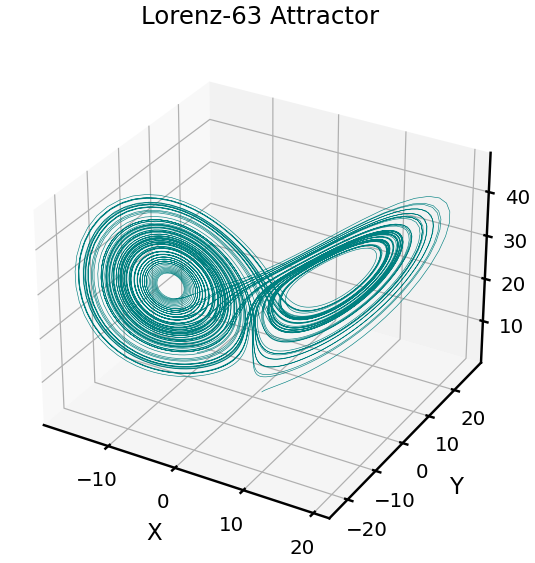

Saved Results/lorenz_attractor.png
Dataset saved as Data/lorenz63_dataset.npy

Module 1 Completed Successfully.


In [3]:
%run Module_1_lorenz63.py

### Module 2

In [4]:
%run Module_2_feature_construction.py

Dataset Loaded. Shape : (10000, 4)
Linear Feature Shape : (9998, 6)
Quadratic Feature Shape : (9998, 21)
Total Reservoir Shape : (9998, 28)
Reservoir Saved: Data/ngrc_reservoir.npy
Feature Names Saved: Data/feature_names.npy

Module 2 Completed Successfully.


### Module 3

In [5]:
%run Module_3_ridge_readout.py

Reservoir Loaded. Shape : (9998, 28)
Dataset Loaded. Shape : (10000, 4)
Target Shape : (9997, 3)
Aligned Reservoir Shape : (9997, 28)
Training Complete. Wout Shape : (3, 28)
Weights Saved to Data/Wout.npy

Module 3 Completed Successfully.


### Module 4

Baseline NGRC Performance
MSE  : 0.026792811054301043
RMSE : 0.16368509722727065
MAE  : 0.10375354148457774
Saved Results/baseline_metrics.csv


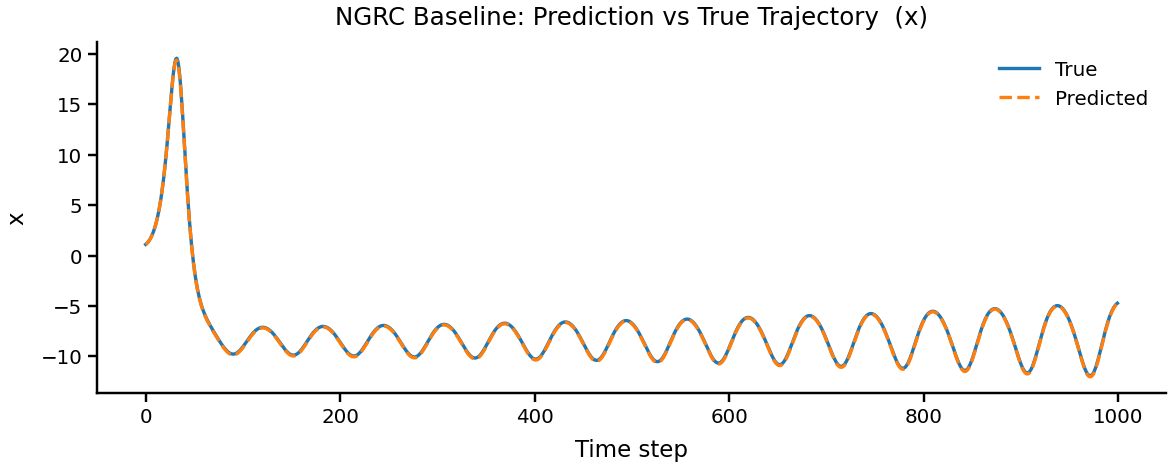

Saved Results/prediction_vs_true_x.png


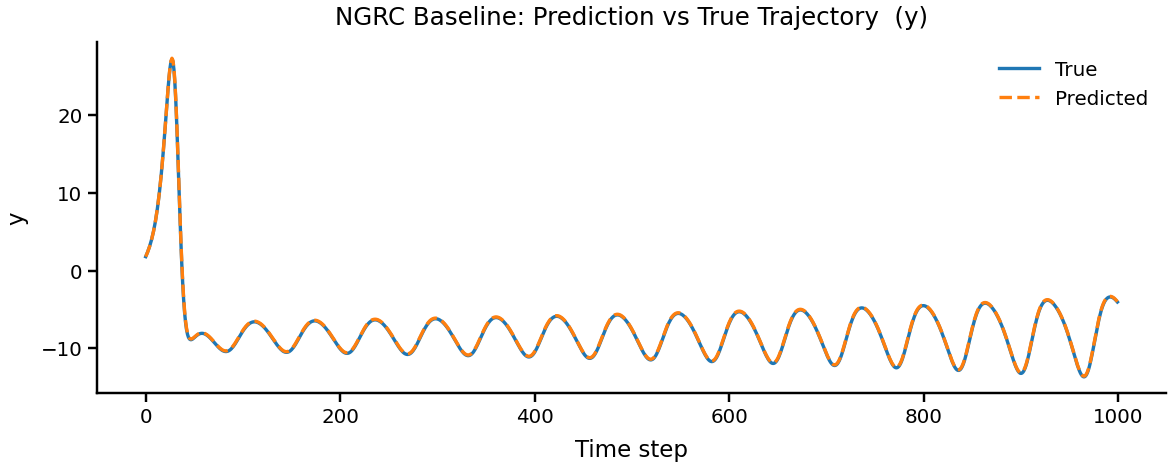

Saved Results/prediction_vs_true_y.png


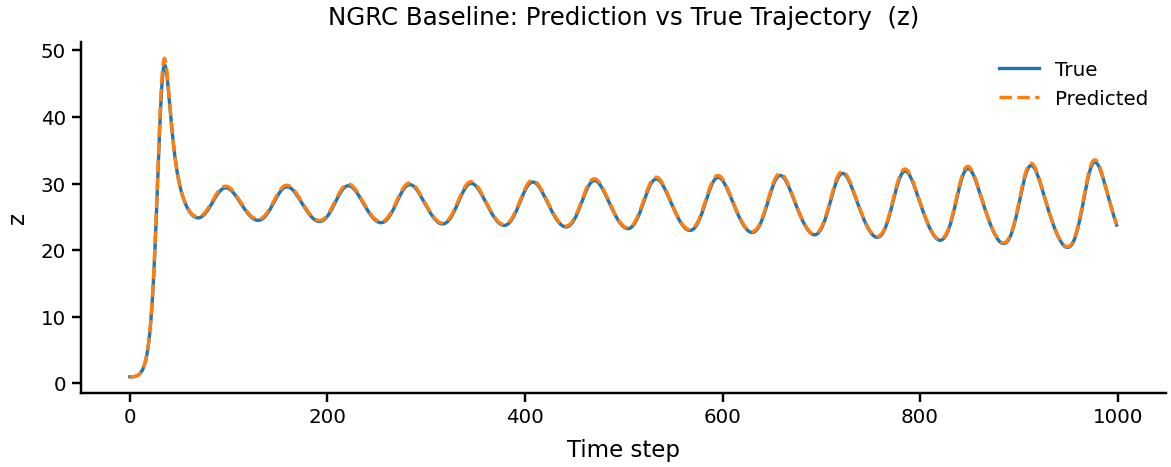

Saved Results/prediction_vs_true_z.png

Module 4 Completed Successfully.


In [6]:
%run Module_4_baseline_experiment.py

### Module 5

Reservoir Shape  : (9997, 28)
Prediction Shape : (9997, 3)
Target Shape     : (9997, 3)

Reference Confidence computed
Mean : 0.9115139680385086
Min  : 0.6468569747557835
Max  : 0.9985620274956069
Saved Data/reference_confidence.npy

Computing Mutual Information...

Top 10 features by |Pearson|:
Feature   Pearson  Pearson_p  Spearman  Spearman_p  Mutual_Information
    x22 -0.990964        0.0 -0.979704         0.0            2.451123
    x10 -0.989978        0.0 -0.975092         0.0            2.317600
     x7 -0.985814        0.0 -0.969251         0.0            1.854555
    x23 -0.863387        0.0 -0.803721         0.0            0.828982
    x11 -0.847836        0.0 -0.792111         0.0            0.766807
    x15 -0.822546        0.0 -0.768311         0.0            0.729855
     x8 -0.806101        0.0 -0.755995         0.0            0.678628
    x18 -0.778077        0.0 -0.779007         0.0            0.734752
     x3 -0.755113        0.0 -0.779007         0.0            0.

C:\Users\B00732999\PycharmProjects\pythonProject\venv\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\B00732999\PycharmProjects\pythonProject\venv\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


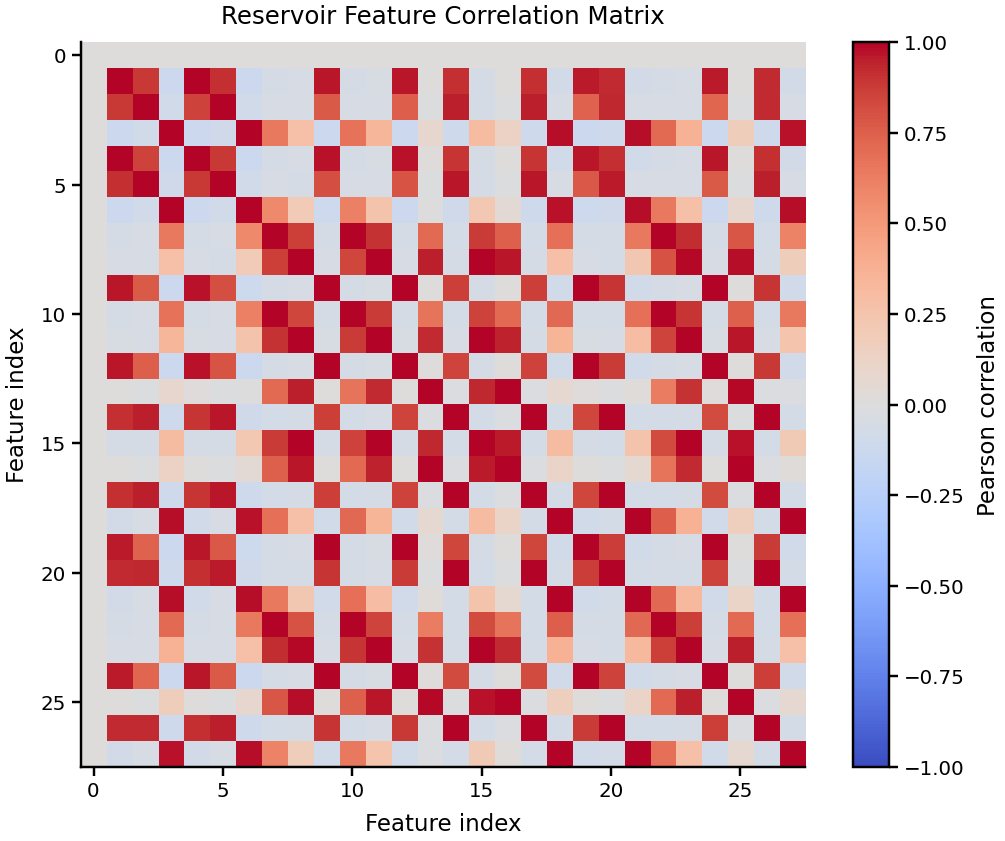

Saved Results/correlation_heatmap.png


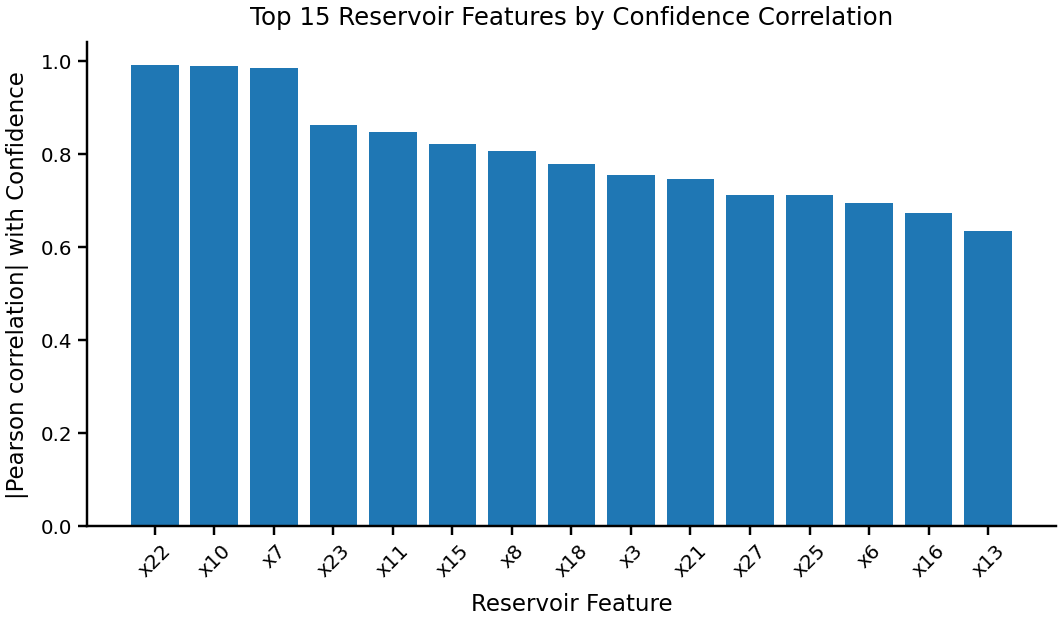

Saved Results/feature_ranking_barplot.png


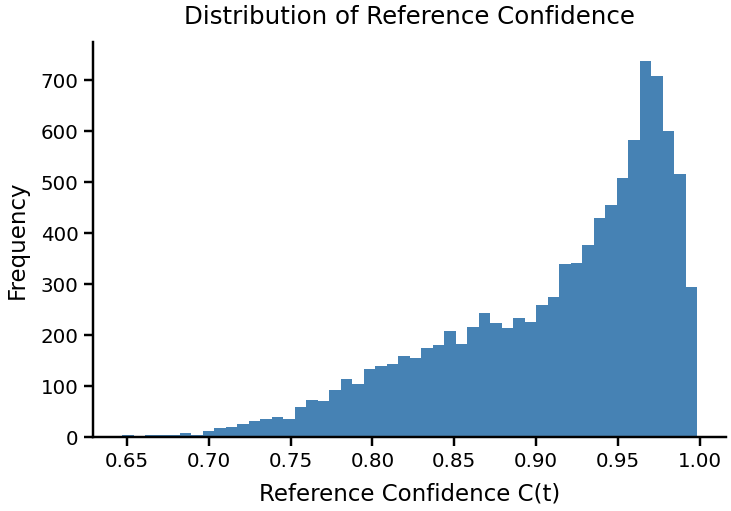

Saved Results/confidence_distribution.png

Module 5 Completed Successfully.


In [7]:
%run Module_5_confidence_analysis.py

### Module 6


Reservoir Loaded. Shape: (9998, 28)
Feature Names Loaded: 28
Reference Confidence Loaded. Shape: (9997,)

Leakage-Free Feature Selection Split
------------------------------------
Total samples    : 9997
Training samples : 7997
Test samples     : 2000

Calculating Pearson correlations using TRAINING DATA ONLY...
Calculating Mutual Information using TRAINING DATA ONLY...


C:\Users\B00732999\PycharmProjects\pythonProject\ RA_work\Mesbin\Module_6_feature_selection.py:126: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(



Feature Ranking Created
------------------------------------
   Index        Feature   Pearson  Pearson_p  Mutual_Information
0     22        x(t-1)² -0.990640        0.0            2.509504
1     10    x(t)·x(t-1) -0.989676        0.0            2.345801
2      7          x(t)² -0.985516        0.0            1.878390
3     23  x(t-1)·y(t-1) -0.863229        0.0            0.844869
4     11    x(t)·y(t-1) -0.847594        0.0            0.777614
5     15    y(t)·x(t-1) -0.822525        0.0            0.748325
6      8      x(t)·y(t) -0.805998        0.0            0.693117
7     18          z(t)² -0.777758        0.0            0.728893
8      3           z(t) -0.754546        0.0            0.726846
9     21    z(t)·z(t-1) -0.745115        0.0            0.682985

Mutual Information Threshold: 0.8112413685746649

Selected Features
------------------------------------
   Index        Feature   Pearson  Pearson_p  Mutual_Information
0     22        x(t-1)² -0.990640        0.0        

C:\Users\B00732999\PycharmProjects\pythonProject\ RA_work\Mesbin\Module_1_lorenz63.py:39: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


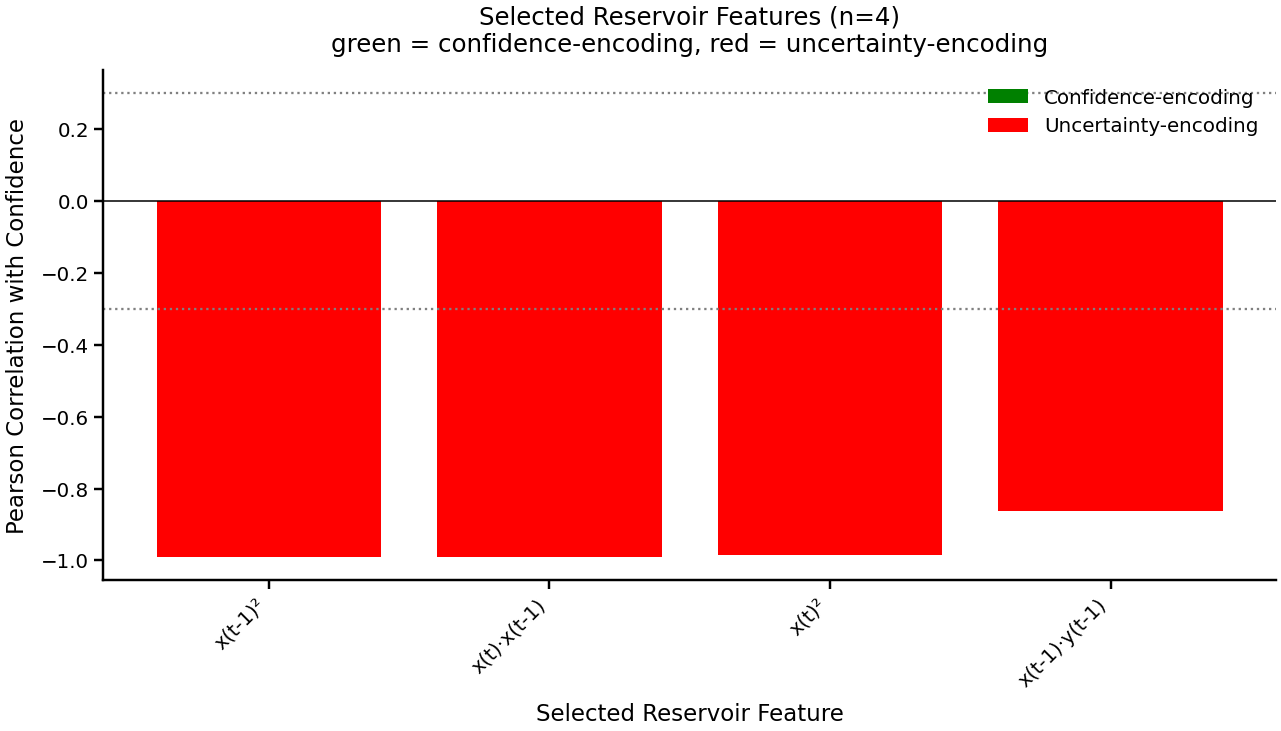

Saved Results/selected_features_plot.png
Saved Results/selected_features_plot.png

Module 6 Completed Successfully.


In [8]:
%run Module_6_feature_selection.py

### Module 7


Confidence Estimator Data
------------------------------------
Selected reservoir shape : (9997, 4)
Reference confidence shape: (9997,)
Total samples            : 9997

Train / Test Split
------------------------------------
Training samples : 7997
Test samples     : 2000

Confidence Estimator Trained
Model: Ridge
Alpha: 0.001

Confidence Estimator Evaluation
------------------------------------
RMSE        : 0.007105
MAE         : 0.005355
R2          : 0.990269
Pearson_r   : 0.995134
Pearson_p   : 0.000000

Model saved to: Results/confidence_model.pkl
Metrics saved to: Results/confidence_metrics.csv
Predictions saved to: Results/confidence_prediction.csv


C:\Users\B00732999\PycharmProjects\pythonProject\ RA_work\Mesbin\Module_1_lorenz63.py:39: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


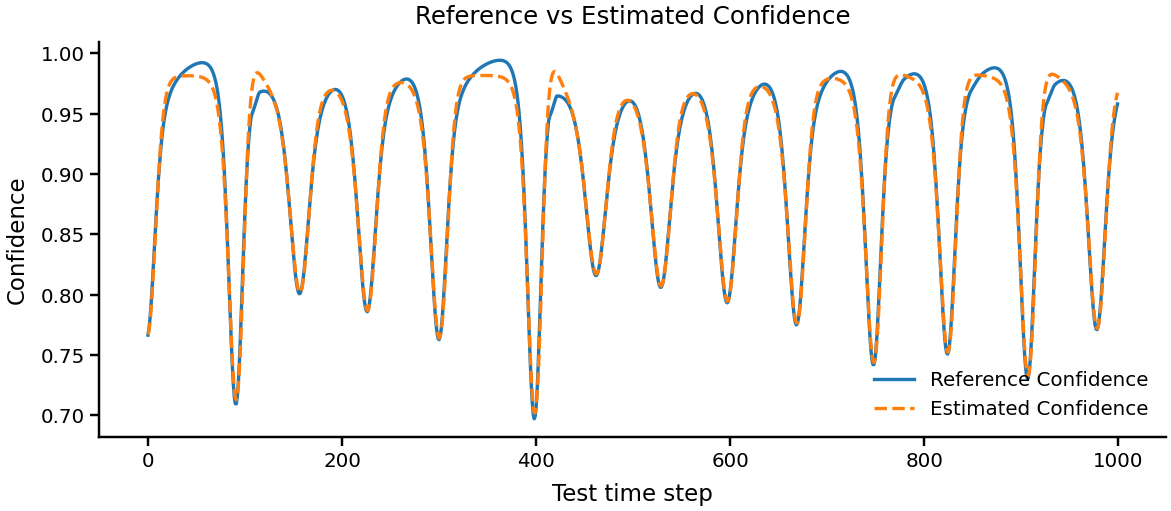

Saved Results/confidence_timeseries.png


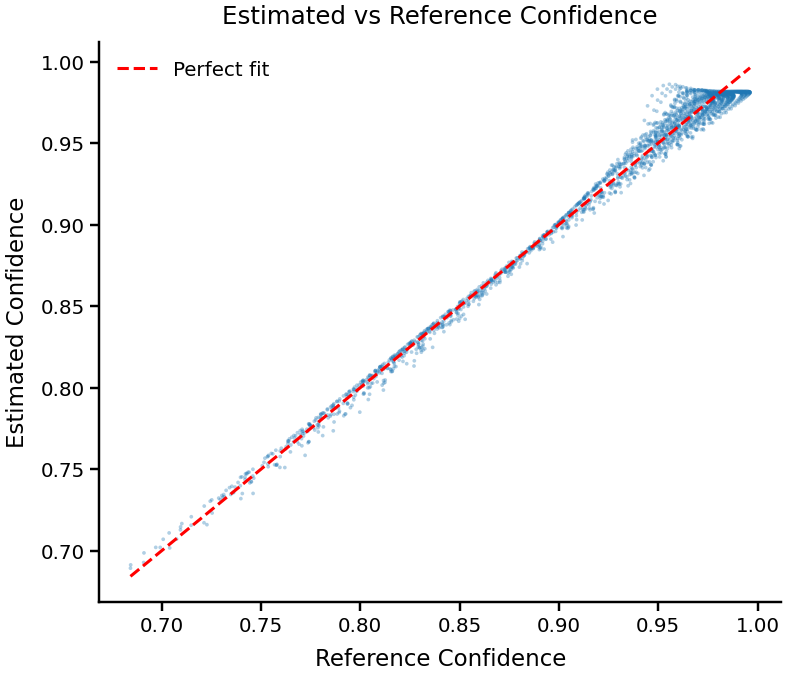

Saved Results/confidence_scatter.png

Module 7 Completed Successfully.

DIAGNOSTIC
-----------------------------
C_test first 10:
[0.76641313 0.77144065 0.77926964 0.78953729 0.80176951 0.81542086
 0.82992045 0.84471782 0.85932226 0.87333104]

C_hat first 10:
[0.76675541 0.77033199 0.77668506 0.78562061 0.79683262 0.80991568
 0.82438779 0.83972275 0.8553888  0.87088755]

Are they exactly identical?
False

Maximum absolute difference:
0.03350167234363066

Mean absolute difference:
0.005355460515755642

Correlation:
0.9951344051697003


In [9]:
%run Module_7_confidence_estimator.py

### Module 8
**Expected:** this module stops with a `ValueError` partway through, in the sensitivity analysis.

That's the same failure as running the GitHub code directly. The analyses before it (confidence definitions, ridge vs linear, ablation) complete and save their results first.


=== Confidence Definitions Comparison ===
  inverse      R2=0.9903  r=0.9951
  exponential  R2=0.9913  r=0.9956
  gaussian     R2=0.9823  r=0.9912
Saved confidence_definitions_comparison.csv

=== Estimator Comparison: Ridge vs Linear Regression ===
           Model     RMSE      MAE       R2  Pearson_r  Pearson_p
           Ridge 0.007105 0.005355 0.990269   0.995134        0.0
LinearRegression 0.007105 0.005355 0.990269   0.995134        0.0

Paired t-test  : t=3.0820, p=2.0841e-03
Wilcoxon test  : W=843044.0000, p=1.0878e-09
Saved statistical_significance.csv

=== Ablation Study: With vs Without Feature Selection ===
  Without_Selection (full reservoir)     n_features= 28  R2=1.0000
  With_Selection (reduced reservoir)     n_features=  4  R2=0.9903
Saved ablation_results.csv

=== Sensitivity Analysis: Pearson Threshold ===
  delta=0.10  n_features= 25  R2=1.0000
  delta=0.20  n_features= 15  R2=0.9999
  delta=0.30  n_features= 15  R2=0.9999
  delta=0.40  n_features= 15  R2=0.9999
  

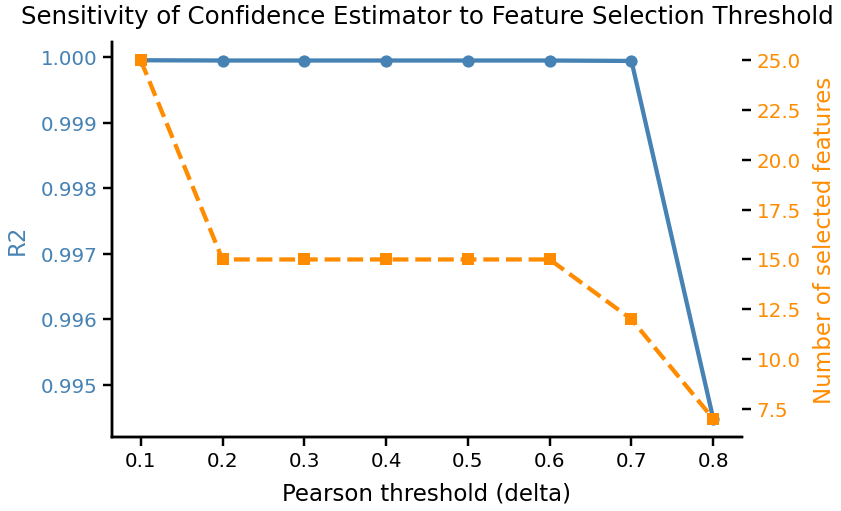

Saved Results/sensitivity_plot.png
Saved sensitivity_results.csv + plot

Saved Results/final_comparison_table.csv

Module 8 Completed Successfully.


In [10]:
%run Module_8_final_validation.py

## 3. Compare with the paper and the README

**Note on one value.** Module 8 crashes before saving its ridge-vs-linear table, but its comparison function had already run. The cell below calls that **same unmodified function** from the GitHub file, on the same saved data, to record the values it produced.

In [11]:
import numpy as np, pandas as pd, io, contextlib
from Module_8_final_validation import compare_estimators

S = np.load("Results/selected_reservoir.npy"); Cref = np.load("Data/reference_confidence.npy")
n_ = min(len(S), len(Cref))
with contextlib.redirect_stdout(io.StringIO()):
    est = compare_estimators(S[:n_], Cref[:n_])
sig = pd.read_csv("Results/statistical_significance.csv").iloc[0]
m7 = pd.read_csv("Results/confidence_metrics.csv").iloc[0]
defs = pd.read_csv("Results/confidence_definitions_comparison.csv").set_index("Definition")
abl = pd.read_csv("Results/ablation_results.csv")
sel = pd.read_csv("Results/selected_features.csv")
lin = est.set_index("Model").loc["LinearRegression"]

rows = [
    # quantity, paper, README, reproduced, decimals to compare at
    ("Selected features (of 28)",               None,     8,        len(sel),                    0),
    ("Estimator RMSE",                          0.00296,  0.002629, m7["RMSE"],                  5),
    ("Estimator R²",                            0.9988,   0.99946,  m7["R2"],                    4),
    ("Estimator Pearson r",                     0.9994,   0.99974,  m7["Pearson_r"],             4),
    ("R², inverse definition",                  0.9988,   None,     defs.loc["inverse","R2"],    4),
    ("R², exponential definition",              0.9989,   None,     defs.loc["exponential","R2"],4),
    ("R², gaussian definition",                 0.9849,   None,     defs.loc["gaussian","R2"],   4),
    ("Pearson r, inverse definition",           0.9994,   None,     defs.loc["inverse","Pearson_r"], 4),
    ("Pearson r, exponential definition",       0.9995,   None,     defs.loc["exponential","Pearson_r"], 4),
    ("Pearson r, gaussian definition",          0.9930,   None,     defs.loc["gaussian","Pearson_r"], 4),
    ("Linear regression RMSE",                  0.002487, None,     lin["RMSE"],                 6),
    ("Linear regression R²",                    0.9991,   None,     lin["R2"],                   4),
    ("Paired t statistic (ridge vs linear)",    9.4636,   None,     sig["Paired_t_stat"],        2),
    ("Wilcoxon W",                              772398,   None,     sig["Wilcoxon_stat"],        0),
    ("Ablation R², full reservoir",             None,     1.0000,   abl.iloc[0]["R2"],           4),
    ("Ablation R², selected features",          None,     0.9995,   abl.iloc[1]["R2"],           4),
]
def verdict(ref, val, d):
    if ref is None: return ""
    return "matches" if round(float(val), d) == round(float(ref), d) else "DIFFERS"
table = pd.DataFrame([{
    "Quantity": q, "Paper": p, "README": r, "Reproduced": (f"{float(v):.{max(d,4)}f}" if d else f"{int(round(float(v)))}"),
    "vs paper": verdict(p, v, d), "vs README": verdict(r, v, d)} for q, p, r, v, d in rows])
table[["Paper", "README"]] = table[["Paper", "README"]].astype(object).where(table[["Paper", "README"]].notna(), "—")
display(table)
print("Sensitivity analysis (README lists sensitivity_plot.png):",
      "produced" if os.path.exists("Results/sensitivity_plot.png") else "NOT produced — Module 8 crashes first")

,Quantity,Paper,README,Reproduced,vs paper,vs README
0,Selected features (of 28),—,8.0,4,,DIFFERS
1,Estimator RMSE,0.00296,0.002629,0.00711,DIFFERS,DIFFERS
2,Estimator R²,0.9988,0.99946,0.9903,DIFFERS,DIFFERS
3,Estimator Pearson r,0.9994,0.99974,0.9951,DIFFERS,DIFFERS
4,"R², inverse definition",0.9988,—,0.9903,DIFFERS,
5,"R², exponential definition",0.9989,—,0.9913,DIFFERS,
6,"R², gaussian definition",0.9849,—,0.9823,DIFFERS,
7,"Pearson r, inverse definition",0.9994,—,0.9951,DIFFERS,
8,"Pearson r, exponential definition",0.9995,—,0.9956,DIFFERS,
9,"Pearson r, gaussian definition",0.993,—,0.9912,DIFFERS,


Sensitivity analysis (README lists sensitivity_plot.png): produced


## 4. Reading the result

- **"matches"** means the published code reproduces the paper's figure at the precision the paper reports.
- **"DIFFERS"** means the paper's figure (or the README's) cannot be produced by the code currently on GitHub. It may come from an earlier version of the code.
- **Nothing in this notebook judges whether the numbers are *valid*.** That's done separately in the review notebook (`NGRC_Lorenz_review.ipynb`). This notebook only answers: *does the published code give the published numbers?*